# Priorización geográfica: señales de reportes SAR hipotecarios

## Pregunta y decisión
¿Cómo cambia la lista de cinco jurisdicciones que merecen análisis exploratorio si priorizamos el volumen de sujetos reportados o la tasa por millón de habitantes? Se contrasta un corte histórico público de FinCEN; sirve para mostrar el efecto de elegir un denominador en una asignación hipotética de revisión, no para clasificar casos individuales de lavado.

Los SAR son reportes de actividad **sospechosa**, no delitos comprobados; un sujeto puede aparecer en más de un reporte. El volumen depende de prácticas de reporte, población y actividad. No hay etiquetas confirmadas, pérdidas, recursos reales ni cálculo de efectividad o precisión.

**Resultado del corte:** coinciden California y Florida entre las cinco jurisdicciones principales por volumen y por tasa. El cruce abarca 51 jurisdicciones con ambas medidas, incluido el Distrito de Columbia.

## Fuente y criterios
[FinCEN, State Mortgage Fraud Suspicious Activity](https://www.fincen.gov/fincen-mortgage-fraud-sar-datasets): archivo XLSX público con sujetos reportados por estado en SAR de sospecha de fraude hipotecario. El archivo local es una instantánea de la fuente y se comprueba por SHA-256. **Último trimestre contenido: 2012 Q2**; los resultados son históricos y no deben orientar cobertura actual.

Se usa en el último corte el conteo de sujetos cuya actividad se registró desde 2010 (`Activity On or after January 1, 2010`) y la tasa publicada por FinCEN en `Subjects Per Capita` para el mismo trimestre; el indicador por millón está publicado por la fuente. El umbral de cinco jurisdicciones es una restricción hipotética, no un objetivo validado. El código requiere pandas, openpyxl y matplotlib.

In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, hashlib
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
p=root/'03-financial-risk/05-enterprise-risk-advisory/05-financial-crime/aml-alert-prioritization/data/fincen_state_mortgage_fraud.xlsx'
sha=hashlib.sha256(p.read_bytes()).hexdigest()
assert sha=='13ffd99a405c2f9885d6dc7e877cc22df94283b0301104d2ee66acf7252724f7'
print('SHA-256 fuente:',sha)
book=pd.ExcelFile(p); print('Pestañas disponibles:',book.sheet_names)

SHA-256 fuente: 13ffd99a405c2f9885d6dc7e877cc22df94283b0301104d2ee66acf7252724f7


Pestañas disponibles: ['Total Subjects', 'Rank by Total Subjects', 'Subjects Per Capita', 'Per Capita Rank', 'Metadata']


## Carga y controles
Los dos cuadros oficiales se unen por abreviatura de estado, preservando sus denominadores. Se exige una fila por estado y se reporta la cobertura del cruce; no se imputan celdas faltantes.

In [2]:
counts=pd.read_excel(book,sheet_name='Total Subjects',header=2)
rates=pd.read_excel(book,sheet_name='Subjects Per Capita',header=1)
count_col='2012 Q2 Activity On or after January 1, 2010';rate_col='2012 Q2'
counts=counts[['State Abbre-viation','State Name',count_col]].rename(columns={'State Abbre-viation':'estado','State Name':'nombre',count_col:'sujetos_recientes'})
rates=rates[['State Abbre-viation',rate_col]].rename(columns={'State Abbre-viation':'estado',rate_col:'sujetos_por_millon'})
counts=counts.dropna(subset=['estado']);rates=rates.dropna(subset=['estado'])
assert counts.estado.is_unique and rates.estado.is_unique
df=counts.merge(rates,on='estado',how='outer',validate='one_to_one',indicator=True)
print('Cobertura del cruce:',df._merge.value_counts().to_dict())
print('Faltantes por variable:',df[['sujetos_recientes','sujetos_por_millon']].isna().sum().to_dict())
df=df.loc[(df._merge=='both') & df.sujetos_recientes.notna() & df.sujetos_por_millon.notna()].copy()
assert (df[['sujetos_recientes','sujetos_por_millon']]>=0).all().all()
print('Jurisdicciones con ambas medidas (incluye DC):',len(df));df.head()

Cobertura del cruce: {'both': 51, 'left_only': 0, 'right_only': 0}
Faltantes por variable: {'sujetos_recientes': 0, 'sujetos_por_millon': 0}
Jurisdicciones con ambas medidas (incluye DC): 51


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/openpyxl/worksheet/header_footer.py:48: UserWarning: Cannot parse header or footer so it will be ignored
  warn("""Cannot parse header or footer so it will be ignored""")


,estado,nombre,sujetos_recientes,sujetos_por_millon,_merge
0,AK,Alaska,5.0,7.039963,both
1,AL,Alabama,37.0,7.741013,both
2,AR,Arkansas,20.0,6.858903,both
3,AZ,Arizona,246.0,38.485505,both
4,CA,California,2284.0,61.308925,both


## Dos reglas de selección
La regla A ordena el volumen; la B ordena la tasa publicada. Los empates se resuelven alfabéticamente por abreviatura para que el resultado sea determinista. Reportamos listas y su intersección: una diferencia no demuestra que una regla sea más efectiva.

In [3]:
K=5
by_count=df.sort_values(['sujetos_recientes','estado'],ascending=[False,True]).head(K)
by_rate=df.sort_values(['sujetos_por_millon','estado'],ascending=[False,True]).head(K)
common=set(by_count.estado)&set(by_rate.estado)
print('Jurisdicciones coincidentes:',len(common),'de',K,sorted(common))
print('Regla A: mayor volumen');display(by_count[['estado','nombre','sujetos_recientes','sujetos_por_millon']].round(2))
print('Regla B: mayor tasa');display(by_rate[['estado','nombre','sujetos_recientes','sujetos_por_millon']].round(2))

Jurisdicciones coincidentes: 2 de 5 ['CA', 'FL']
Regla A: mayor volumen


,estado,nombre,sujetos_recientes,sujetos_por_millon
4,CA,California,2284.0,61.31
9,FL,Florida,727.0,38.67
34,NY,New York,541.0,27.92
14,IL,Illinois,335.0,26.11
43,TX,Texas,308.0,12.25


Regla B: mayor tasa


,estado,nombre,sujetos_recientes,sujetos_por_millon
4,CA,California,2284.0,61.31
33,NV,Nevada,119.0,44.07
9,FL,Florida,727.0,38.67
3,AZ,Arizona,246.0,38.49
5,CO,Colorado,142.0,28.24


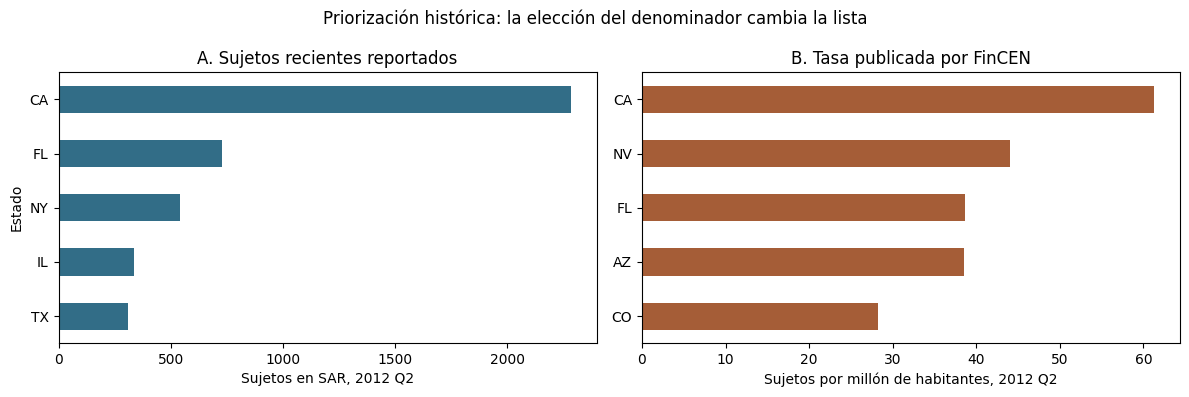

In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
by_count.sort_values('sujetos_recientes').plot.barh(x='estado',y='sujetos_recientes',ax=axes[0],legend=False,color='#326d87');axes[0].set(title='A. Sujetos recientes reportados',xlabel='Sujetos en SAR, 2012 Q2',ylabel='Estado')
by_rate.sort_values('sujetos_por_millon').plot.barh(x='estado',y='sujetos_por_millon',ax=axes[1],legend=False,color='#a55d37');axes[1].set(title='B. Tasa publicada por FinCEN',xlabel='Sujetos por millón de habitantes, 2012 Q2',ylabel='')
fig.suptitle('Priorización histórica: la elección del denominador cambia la lista');plt.tight_layout();plt.show()

## Sensibilidad a la capacidad
El tamaño de la lista es una decisión operativa. La intersección para 3, 5 y 10 estados muestra cuán diferente resulta cada regla bajo capacidades alternativas; no evalúa productividad, tasa de aciertos o representatividad de los reportes.

In [5]:
rows=[]
for k in (3,5,10):
 a=set(df.sort_values(['sujetos_recientes','estado'],ascending=[False,True]).head(k).estado)
 b=set(df.sort_values(['sujetos_por_millon','estado'],ascending=[False,True]).head(k).estado)
 rows.append({'capacidad_estados':k,'coincidentes':len(a&b),'fracción_coincidente':len(a&b)/k})
pd.DataFrame(rows)

,capacidad_estados,coincidentes,fracción_coincidente
0,3,2,0.666667
1,5,2,0.400000
2,10,7,0.700000


## Uso y límites
Para una aplicación de priorización de alertas se requieren alertas por caso, fecha de disponibilidad, variables autorizadas, decisiones, hallazgos confirmados, costes de investigación y evaluación temporal. Este dataset agregado no identifica esos elementos ni valida un sistema AML; tampoco mide probabilidad de fraude. Antes de usar información actual, confirmar definiciones y actualizaciones de la fuente y revisar sesgos de reporte.